# NB2 experiment: 30% systematic label noise and early stopping

**COMP3620 CW3**

## The question

Does early stopping still protect a network from label noise when the mistakes are systematic rather than random?

## What NB2 does

NB1 reproduced the known result: under 30% random noise, the network learns the true digits first and memorises the wrong labels later, so early stopping keeps most of the test accuracy.

NB2 changes exactly one thing, the **type** of noise. Each selected image is relabelled as the next digit, `c → (c + 1) mod 10` (pair flipping, Han et al., 2018). The noise ratio, the selected images, the data split, the model and the training settings are all the same as in NB1.

NB2 covers:

- the theory and pre-registered predictions P5 and P6, committed before any result is generated;
- 30% systematic noise and a check of the corrupted labels;
- learning-rate tuning for the systematic condition, with at least three seeds;
- a comparison with the clean and random results from NB1;
- tests of P5 and P6, and analyses that rule out alternative explanations;
- a sensitivity check;
- scope, limitations and next steps.

NB2 reads NB1's cached results from `results/`, so NB1 does not need to be run first.


## Theory and pre-registered predictions

*Written and committed before any systematic run was trained.*

### Why systematic noise should be harder

Take every training image whose true digit is 3 and look at the labels it was given:

| | labelled 3 | labelled 4 | labelled each other digit |
|---|---|---|---|
| random noise | 70% | ≈ 3.3% | ≈ 3.3% |
| systematic noise | 70% | 30% | 0% |

Early in training, a network learns the label that is most common for each kind of image. Under random noise the true label leads by about 21 to 1, and the wrong labels point in different directions, so their gradients largely cancel (coherent gradients, Chatterjee, 2020). They can only be memorised one image at a time, late in training.

Under systematic noise the true label still wins, but only by 7 to 3, and every wrong label points the same way. "c → c + 1" then behaves like a second rule that the network can learn. We therefore expect predictions to be pulled towards the next digit early in training, before the early-stopping epoch, and not only during late memorisation.

### Can a noisy validation set still choose the stopping epoch?

We stop at the epoch with the highest noisy-validation accuracy, because clean validation labels are not available in practice. Let a be the true validation accuracy and b the fraction of corrupted validation images predicted as the next digit. Then

  noisy validation accuracy ≈ a(1 − η) + bη.

Under random noise b stays small, so the noisy accuracy follows a (NB1, P4). Under systematic noise b can grow. An example with 1,000 validation images, 700 correctly labelled and 300 flipped:

| epoch | true accuracy a | where the errors go | noisy validation accuracy |
|---|---|---|---|
| A | 90% | spread over all digits | (630 + 3) / 1000 = 63.3% |
| B | 88% | 90% of errors on the next digit | (616 + 32) / 1000 = 64.8% |

The noisy validation set prefers B, although A is better on the true labels. We do not predict whether this happens in our runs; it is analysed separately after P5 and P6.

### Predictions

**P5, main hypothesis.** With the same 30% noise ratio, early stopping protects clearly less under systematic noise than under random noise.

**P6.** Under systematic noise, test errors concentrate on the next digit. Under random noise and clean labels, the share of test errors on the next digit stays near 1/9.

### Metrics and thresholds, fixed now

The primary metric is the same as in NB1: test accuracy at the noisy-validation early-stopping epoch, as a mean over seeds 0 to 2, each condition at its own selected learning rate.

Baseline from NB1's cached results, known before writing these thresholds: random early-stopping test accuracy 93.41% (seeds 92.85%, 93.47%, 93.91%); share of test errors on the next digit at the final epoch, clean 0.097 and random 0.109.

- **P5 holds if both are true:**
  - the mean early-stopping test accuracy under systematic noise is at least **2 percentage points** below the random mean;
  - every systematic seed is below the lowest random seed.
- **P6 holds if all are true**, using `test_err_next` at each run's early-stopping epoch, mean over seeds:
  - systematic ≥ **0.50**;
  - random < **0.20**;
  - clean < **0.20**.


In [ ]:
QUICK = True  # True: load the cached runs and finish in < 5 min; False: run the full experiment

## Shared protocol, from the group worksheet

| Item | Setting |
|---|---|
| Dataset | MNIST, `torchvision.datasets.MNIST` |
| Train | `train=True` images `[0:10000]`, 10,000 |
| Validation | `train=True` images `[50000:55000]`, 5,000 |
| Test | `train=False` images, 10,000; never corrupted |
| Input | pixels scaled to 0 to 1, flattened to 784 |
| Model | MLP 784 → 512 → 512 → 10, ReLU, PyTorch default init |
| Regularisation | none: no dropout, weight decay, BatchNorm, or data augmentation |
| Loss / optimiser | cross-entropy; Adam with default betas/eps, no weight decay |
| Batch size | 128, reshuffled every epoch |
| Epochs | 200, no early stopping during training; evaluate after every epoch |
| Early stopping | after training: epoch with highest **noisy** validation accuracy |
| Noise | η = 0.30, 30% of each class, rounded to the nearest whole image |
| Seeds | 0, 1, 2, plus 3 and 4 if time |
| Learning rates | 1e-4, 3e-4, 1e-3, 3e-3 |


In [70]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

ROOT = Path(".")
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
for p in (DATA_DIR, RESULTS_DIR, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)

NOISE_RATIO = 0.30 # 30% of each class is corrupted
NUM_CLASSES = 10
EPOCHS = 200       # train to the end
BATCH_SIZE = 128
HIDDEN = 512
LR_CANDIDATES = [1e-4, 3e-4, 1e-3, 3e-3]
SEEDS = [0, 1, 2]
CONDITIONS_NB1 = ["clean", "random"]  # conditons of NB1, NB2 would be systemetic
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("device:", DEVICE)
print("torch:", torch.__version__)
print("results dir:", RESULTS_DIR.resolve())


device: cpu
torch: 2.15.0
results dir: /Users/alexw/Desktop/3620project/results


In [71]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


## 1. Data and fixed split

The split is fixed once and reused by every seed and every condition. It does not depend on the model or on the noise type.

| Part | Source | Size | Labels |
|---|---|---|---|
| Train | `train=True` images `[0:10000]` | 10,000 | changed according to condition |
| Validation | `train=True` images `[50000:55000]` | 5,000 | changed in the same way; clean copy kept for analysis |
| Test | `train=False` images | 10,000 | never changed |


In [72]:
def load_mnist_split():
    tf = transforms.ToTensor()
    train_full = datasets.MNIST(DATA_DIR, train=True, download=True, transform=tf)
    test_full = datasets.MNIST(DATA_DIR, train=False, download=True, transform=tf)

    train_idx = list(range(0, 10_000))
    val_idx = list(range(50_000, 55_000))

    def to_tensors(dataset):
        xs, ys = [], []
        for x, y in dataset:
            xs.append(x.reshape(-1))
            ys.append(int(y))
        return torch.stack(xs), torch.tensor(ys, dtype=torch.long)

    train_x, train_y = to_tensors(Subset(train_full, train_idx))
    val_x, val_y = to_tensors(Subset(train_full, val_idx))
    test_x, test_y = to_tensors(test_full)
    return train_x, train_y, val_x, val_y, test_x, test_y

train_x, train_y, val_x, val_y, test_x, test_y = load_mnist_split()
data = (train_x, train_y, val_x, val_y, test_x, test_y)

print("train:", tuple(train_x.shape), tuple(train_y.shape), "counts:", np.bincount(train_y.numpy()))
print("val:  ", tuple(val_x.shape), tuple(val_y.shape), "counts:", np.bincount(val_y.numpy()))
print("test: ", tuple(test_x.shape), tuple(test_y.shape), "counts:", np.bincount(test_y.numpy()))
print("pixel range:", float(train_x.min()), float(train_x.max()))


train: (10000, 784) (10000,) counts: [1001 1127  991 1032  980  863 1014 1070  944  978]
val:   (5000, 784) (5000,) counts: [502 534 497 521 484 457 485 527 515 478]
test:  (10000, 784) (10000,) counts: [ 980 1135 1032 1010  982  892  958 1028  974 1009]
pixel range: 0.0 1.0


## 2. Label noise

- **Random, symmetric:** each selected image is assigned a label drawn uniformly from the other 9 classes; the assigned label is always wrong.
- **Systematic, pair flipping, NB2:** each selected image is assigned the label `c + 1` modulo 10.
- **Clean:** labels unchanged, but the same mask is returned for analysis.

The mask is generated first from `np.random.default_rng`, seeded with the pair `seed` and `split_id`, so it is identical for clean/random/systematic. Training uses `split_id=0`; validation uses `split_id=1`; the test set is never touched.

We use integer labels, so no one-hot regeneration is needed. If the lab machine has no internet, pre-download MNIST into `data/` before running the notebook.

Because the fixed 10k/5k splits are not exactly balanced across classes, the number selected per class is rounded to the nearest image. The realised ratio therefore differs from 30% by at most 0.5 image per class; the check below prints the actual per-class ratios.


In [73]:
def make_mask(labels, ratio, rng):
    labels = np.asarray(labels)
    mask = np.zeros(len(labels), dtype=bool)
    for c in range(NUM_CLASSES):
        idx = np.flatnonzero(labels == c)
        n = int(round(len(idx) * ratio))
        if n > 0:
            mask[rng.choice(idx, size=n, replace=False)] = True
    return mask


def corrupt_labels(labels, noise_type, ratio, seed, split_id):
    labels = np.asarray(labels)
    rng = np.random.default_rng([seed, split_id])
    # Generate the mask first: it is identical for clean/random/systematic.
    mask = make_mask(labels, ratio, rng)
    corrupted = labels.copy()

    if noise_type == "random" and mask.any():
        true = labels[mask]
        wrong = rng.integers(0, NUM_CLASSES - 1, size=len(true))
        wrong = np.where(wrong >= true, wrong + 1, wrong)  # uniformly skip the true class
        corrupted[mask] = wrong
    elif noise_type == "systematic" and mask.any():
        corrupted[mask] = (labels[mask] + 1) % NUM_CLASSES
    elif noise_type == "clean":
        pass
    else:
        raise ValueError(f"unknown noise_type: {noise_type}")

    return corrupted, mask


def transition_table(true_labels, given_labels, mask=None, only_masked=False):
    """10x10 table of true digit against given label, row-normalised.

    By default every image of a class is counted, which is the orientation the
    shared protocol specifies: under 30% random noise the diagonal is 0.70 and
    each of the other nine cells is about 0.033; under paired flipping the
    diagonal is 0.70 and the "next digit" cell is 0.30.

    only_masked=True restricts the table to the corrupted images, giving diagonal
    0 and 1/9 per off-diagonal cell under random noise. That answers a different
    question, namely what a corrupted image was corrupted to, and is kept as a
    secondary view.
    """
    true_labels = np.asarray(true_labels)
    given_labels = np.asarray(given_labels)
    if mask is not None and only_masked:
        true_labels = true_labels[mask]
        given_labels = given_labels[mask]
    table = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
    for t, g in zip(true_labels, given_labels):
        table[t, g] += 1
    row_sums = table.sum(axis=1, keepdims=True)
    return table, table / np.maximum(row_sums, 1)


def check_transition(labels, corrupted, mask, noise_type, n_sigma=4.5):
    """Check a noise table against the shape the shared protocol predicts.

    Tolerances are derived from the actual class counts instead of being hard-coded.
    The diagonal is exact by construction, because the mask corrupts round(r * n_c)
    images of class c, so the diagonal is 1 - round(r * n_c) / n_c, and it gets a
    tight tolerance. An off-diagonal cell holds about r * n_c / 9 corrupted images
    and is therefore a binomial count, with normalised standard deviation
    sqrt((r/9)/n_c); the tolerance is n_sigma of that. A fixed tolerance would
    either fail at random on the 5,000-image validation split or be too loose to
    detect a real error.
    """
    labels = np.asarray(labels)
    _, row_norm = transition_table(labels, corrupted)
    diag = np.diag(row_norm)

    counts = np.bincount(labels, minlength=NUM_CLASSES)
    n_min = max(int(counts[counts > 0].min()), 1)
    diag_tol = 0.5 / n_min + 0.002
    cell_tol = n_sigma * float(np.sqrt((NOISE_RATIO / (NUM_CLASSES - 1)) / n_min))

    if noise_type == "systematic":
        next_digit = np.array([row_norm[c, (c + 1) % NUM_CLASSES] for c in range(NUM_CLASSES)])
        others = row_norm.copy()
        for c in range(NUM_CLASSES):
            others[c, c] = 0.0
            others[c, (c + 1) % NUM_CLASSES] = 0.0
        ok = (
            np.all(np.abs(diag - (1 - NOISE_RATIO)) <= diag_tol)
            and np.all(np.abs(next_digit - NOISE_RATIO) <= cell_tol)
            and np.all(others <= cell_tol)
        )
        detail = (f"diagonal {diag.min():.3f} to {diag.max():.3f}, want {1 - NOISE_RATIO:.2f} +/-{diag_tol:.3f}, "
                  f"next digit {next_digit.min():.3f} to {next_digit.max():.3f}, want {NOISE_RATIO:.2f} +/-{cell_tol:.3f}, "
                  f"all other cells <= {others.max():.3f}")
        return ok, row_norm, detail

    off = row_norm[~np.eye(NUM_CLASSES, dtype=bool)]
    target = NOISE_RATIO / (NUM_CLASSES - 1)
    ok = (
        np.all(np.abs(diag - (1 - NOISE_RATIO)) <= diag_tol)
        and np.all(np.abs(off - target) <= cell_tol)
    )
    detail = (f"diagonal {diag.min():.3f} to {diag.max():.3f}, want {1 - NOISE_RATIO:.2f} +/-{diag_tol:.3f}, "
              f"off-diagonal {off.min():.3f} to {off.max():.3f}, want {target:.3f} +/-{cell_tol:.3f}")
    return ok, row_norm, detail


def check_noise(labels, seed, split_id, name):
    labels = np.asarray(labels)
    print(f"\n=== {name} | seed {seed} ===")
    masks = {}
    for noise_type in ["clean", "random", "systematic"]:
        corrupted, mask = corrupt_labels(labels, noise_type, NOISE_RATIO, seed, split_id)
        masks[noise_type] = mask
        ratios = [
            ((labels == c) & mask).sum() / max((labels == c).sum(), 1)
            for c in range(NUM_CLASSES)
        ]
        print(f"{noise_type:10s} per-class ratio: min={min(ratios):.4f} max={max(ratios):.4f}")
        if noise_type in ("random", "systematic"):
            ok, row_norm, detail = check_transition(labels, corrupted, mask, noise_type)
            print("  full transition table, rows = true digit, cols = given label:")
            print(np.round(row_norm, 3))
            print(f"  check: {detail}  -> {'PASS' if ok else 'FAIL'}")
            _, masked_norm = transition_table(labels, corrupted, mask, only_masked=True)
            print("  restricted to corrupted images only, secondary view:")
            print(np.round(masked_norm, 3))

    same = (
        np.array_equal(masks["clean"], masks["random"])
        and np.array_equal(masks["clean"], masks["systematic"])
    )
    print("same mask across noise types:", same)


check_noise(train_y.numpy(), seed=0, split_id=0, name="train")
check_noise(val_y.numpy(), seed=0, split_id=1, name="val")

print("\nCompact check across all seeds:")
for s in SEEDS:
    for split_id, labels, name in [(0, train_y.numpy(), "train"), (1, val_y.numpy(), "val")]:
        masks = {}
        ratios_ok = True
        for nt in ["clean", "random", "systematic"]:
            _, m = corrupt_labels(labels, nt, NOISE_RATIO, s, split_id)
            masks[nt] = m
            ratios = [((labels == c) & m).sum() / max((labels == c).sum(), 1) for c in range(NUM_CLASSES)]
            # Counts are rounded to the nearest image, so the realised ratio can differ
            # from 0.30 by at most 0.5 image per class.
            ratios_ok = ratios_ok and all(
                abs(r - NOISE_RATIO) <= 0.5 / max((labels == c).sum(), 1) + 1e-12
                for c, r in enumerate(ratios)
            )
        same = (
            np.array_equal(masks["clean"], masks["random"])
            and np.array_equal(masks["clean"], masks["systematic"])
        )
        print(f"seed {s} {name}: ratios_ok={ratios_ok}, same_mask={same}")



=== train | seed 0 ===
clean      per-class ratio: min=0.2996 max=0.3004
random     per-class ratio: min=0.2996 max=0.3004
  full transition table, rows = true digit, cols = given label:
[[0.7   0.037 0.042 0.024 0.03  0.023 0.036 0.032 0.039 0.037]
 [0.035 0.7   0.03  0.043 0.036 0.027 0.032 0.028 0.035 0.034]
 [0.031 0.03  0.7   0.037 0.039 0.035 0.025 0.034 0.038 0.028]
 [0.044 0.021 0.037 0.7   0.036 0.021 0.04  0.041 0.031 0.03 ]
 [0.037 0.037 0.037 0.03  0.7   0.037 0.027 0.033 0.032 0.033]
 [0.03  0.028 0.034 0.031 0.035 0.7   0.032 0.049 0.028 0.034]
 [0.039 0.035 0.033 0.036 0.033 0.036 0.7   0.04  0.029 0.019]
 [0.034 0.039 0.033 0.033 0.029 0.036 0.034 0.7   0.038 0.024]
 [0.036 0.033 0.03  0.034 0.03  0.035 0.032 0.034 0.7   0.037]
 [0.027 0.04  0.036 0.024 0.029 0.039 0.03  0.037 0.04  0.7  ]]
  check: diagonal 0.700 to 0.700, want 0.70 +/-0.003, off-diagonal 0.019 to 0.049, want 0.033 +/-0.028  -> PASS
  restricted to corrupted images only, secondary view:
[[0.    0.123 

## 3. Model and training protocol

Design choices and rationale:

- **10,000 training images.** Small enough that a high-capacity MLP can memorise the noisy labels within 200 epochs, and large enough that the clean pattern is still learnable.
- **784 → 512 → 512 → 10 MLP.** Enough capacity to fit the training set; PyTorch default initialisation; ReLU.
- **No regularisation.** No dropout, weight decay, BatchNorm, or data augmentation. These would slow memorisation and make it unclear whether a difference is due to the noise type or to regularisation. This is also a scope limitation.
- **Adam, default betas/eps, no weight decay; batch size 128; 200 epochs.** Fixed for every seed and condition. No early stopping during training, so the full curve is available; the stopping epoch is chosen afterwards from the noisy validation curve.
- **Cross-entropy**, integer labels. The test set is evaluated after every epoch but is never used for tuning or stopping.

The function `train_one_run` below is the shared training function. **NB2 must copy this whole training block** `set_seed`, `corrupt_labels`, `MLP`, `predict`, `compute_metrics`, `train_one_run` verbatim, so that the only difference is the noise type.

### What the seed controls

Per the shared protocol the seed fixes three channels and nothing else:

- **which images are corrupted and what they are corrupted to**, from `np.random.default_rng` with the pair `seed` and `split_id`, where `split_id=0` is train and `split_id=1` is validation. The mask depends on the seed only, so all three noise types corrupt the same images;
- **weight initialisation**, from `torch.manual_seed` inside `set_seed`;
- **batch order**, from a separate `torch.Generator` seeded with the same seed.

The split, the test set and the dropout masks are not affected: the split is fixed in code, the test set is never touched, and this model has no dropout. Because the mask is a function of the seed, the three seeds are three independent noise realisations, so the spread in section 5 covers both initialisation noise and noise-realisation noise.


In [74]:
class MLP(nn.Module):
    def __init__(self, hidden=HIDDEN, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, num_classes),
        )

    def forward(self, x):
        return self.net(x)


@torch.inference_mode()
def predict(model, loader):
    model.eval()
    preds = []
    for x, _ in loader:
        preds.append(model(x.to(DEVICE)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()


def compute_metrics(model, train_loader, val_loader, test_loader,
                    train_y_clean, train_y_given, train_mask,
                    val_y_clean, val_y_given, test_y, condition):
    train_pred = predict(model, train_loader)
    val_pred = predict(model, val_loader)
    test_pred = predict(model, test_loader)

    train_acc_given = float((train_pred == train_y_given).mean())

    if train_mask.any():
        selected_pred_true = float((train_pred[train_mask] == train_y_clean[train_mask]).mean())
        nonselected_pred_true = (
            float((train_pred[~train_mask] == train_y_clean[~train_mask]).mean())
            if (~train_mask).any() else None
        )
        selected_pred_given = (
            None if condition == "clean"
            else float((train_pred[train_mask] == train_y_given[train_mask]).mean())
        )
    else:
        selected_pred_true = None
        nonselected_pred_true = None
        selected_pred_given = None

    val_acc_noisy = float((val_pred == val_y_given).mean())
    val_acc_clean = float((val_pred == val_y_clean).mean())
    test_acc = float((test_pred == test_y).mean())

    errors = test_pred != test_y
    if errors.any():
        next_digit = (test_y + 1) % NUM_CLASSES
        test_err_next = float((test_pred[errors] == next_digit[errors]).mean())
    else:
        test_err_next = None

    return {
        "epoch": None,
        "train_acc_given": train_acc_given,
        "selected_pred_true": selected_pred_true,
        "selected_pred_given": selected_pred_given,
        "nonselected_pred_true": nonselected_pred_true,
        "val_acc_noisy": val_acc_noisy,
        "val_acc_clean": val_acc_clean,
        "test_acc": test_acc,
        "test_err_next": test_err_next,
    }


def train_one_run(condition, lr, seed, data, epochs=EPOCHS, batch_size=BATCH_SIZE,
                  demo=False, verbose=True):
    train_x, train_y_clean_t, val_x, val_y_clean_t, test_x, test_y_t = data
    set_seed(seed)

    train_y_clean = train_y_clean_t.numpy()
    val_y_clean = val_y_clean_t.numpy()
    test_y = test_y_t.numpy()

    train_y_given, train_mask = corrupt_labels(
        train_y_clean, condition, NOISE_RATIO, seed, split_id=0
    )
    val_y_given, _ = corrupt_labels(
        val_y_clean, condition, NOISE_RATIO, seed, split_id=1
    )

    if demo:
        n_train = min(2000, len(train_x))
        n_val = min(1000, len(val_x))
        n_test = min(1000, len(test_x))
        train_x = train_x[:n_train]
        train_y_clean = train_y_clean[:n_train]
        train_y_given = train_y_given[:n_train]
        train_mask = train_mask[:n_train]
        val_x = val_x[:n_val]
        val_y_clean = val_y_clean[:n_val]
        val_y_given = val_y_given[:n_val]
        test_x = test_x[:n_test]
        test_y = test_y[:n_test]

    train_ds = TensorDataset(train_x, torch.tensor(train_y_given, dtype=torch.long))
    val_ds = TensorDataset(val_x, torch.tensor(val_y_given, dtype=torch.long))
    test_ds = TensorDataset(test_x, torch.tensor(test_y, dtype=torch.long))

    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g)
    train_eval_loader = DataLoader(train_ds, batch_size=512, shuffle=False)
    val_loader = DataLoader(val_ds, batch_size=512, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=512, shuffle=False)

    model = MLP().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # default betas/eps, no weight decay
    loss_fn = nn.CrossEntropyLoss()

    history = []
    t0 = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()

        metrics = compute_metrics(
            model, train_eval_loader, val_loader, test_loader,
            train_y_clean, train_y_given, train_mask,
            val_y_clean, val_y_given, test_y, condition,
        )
        metrics["epoch"] = epoch
        history.append(metrics)

        if verbose and (epoch % 20 == 0 or epoch == epochs):
            print(
                f"  epoch {epoch:3d}/{epochs} | train {metrics['train_acc_given']:.3f} "
                f"| val noisy {metrics['val_acc_noisy']:.3f} | test {metrics['test_acc']:.3f}"
            )

    val_noisy = np.array([h["val_acc_noisy"] for h in history])
    test_acc = np.array([h["test_acc"] for h in history])
    best_epoch = int(np.argmax(val_noisy)) + 1
    optimal_test_epoch = int(np.argmax(test_acc)) + 1

    metrics_dict = {key: [h[key] for h in history] for key in history[0]}

    return {
        "config": {
            "condition": condition,
            "lr": float(lr),
            "seed": int(seed),
            "epochs": int(epochs),
            "batch_size": int(batch_size),
            "noise_ratio": float(NOISE_RATIO),
            "noise_type": condition,
            "num_classes": int(NUM_CLASSES),
            "hidden": int(HIDDEN),
            "model": "MLP 784-512-512-10, ReLU, PyTorch default init",
            "regularisation": "none: no dropout, weight decay, BatchNorm, or augmentation",
            "optimizer": "Adam, default betas/eps, no weight decay",
            "dataset": "MNIST",
            "split": "train [0:10000], val [50000:55000], test all 10000",
            "seeds": [int(x) for x in SEEDS],
            "lr_candidates": [float(x) for x in LR_CANDIDATES],
            "demo": bool(demo),
            "torch_version": torch.__version__,
            "device": str(DEVICE),
        },
        "metrics": metrics_dict,
        "early_stop": {
            "epoch": best_epoch,
            "val_acc_noisy": float(val_noisy[best_epoch - 1]),
            "test_acc_at_stop": float(test_acc[best_epoch - 1]),
            "test_acc_last10_mean": float(test_acc[-10:].mean()),
            "max_test_acc": float(test_acc.max()),
            "optimal_test_epoch": optimal_test_epoch,
            "gap_to_optimal_test_acc": float(test_acc.max() - test_acc[best_epoch - 1]),
        },
        "wall_time_s": float(time.perf_counter() - t0),
    }


## 4. Training runs for the systematic condition

The systematic condition is trained with the same four learning rates and the same three seeds as NB1: 4 × 3 = 12 runs, each of 200 epochs. Together with NB1's 24 runs, this completes the project's 36-run grid. The learning rate is then selected in the same way as in NB1, by the highest mean early-stopping noisy-validation accuracy over the three seeds (section 5).

This section has three parts:

- **4.1 Cache helpers.** Each run is saved as one JSON file, `results/{condition}_lr{lr}_seed{seed}.json`. The naming is the same as in NB1, so runs from both notebooks are read in the same way.
- **4.2 Systematic runs.** With `QUICK = True`, the 12 cached runs are loaded. If the cache is incomplete, raise Error. With `QUICK = False`, each run is trained and saved; a run whose file already exists is loaded instead of retrained, so an interrupted session can resume. Because every run is fixed by its seed, loading a finished run gives the same result as retraining it.
- **4.3 NB1 results.** The 24 clean and random runs are loaded from NB1's cache, so the three conditions can be compared in the following sections.


### 4.1 Cache helpers

Three small functions: `result_path` gives the file name of a run, `save_result` writes a run to that file, and `load_result` reads it back.


In [75]:
def result_path(condition, lr, seed):

    file_name = f"{condition}_lr{lr:g}_seed{seed}.json"  # combine the parameter to create a name for each run
    
    return RESULTS_DIR / file_name  # save in the results folder

def save_result(result):

    cfg = result["config"]  # get the configuration from dictionary
    path = result_path(cfg["condition"], cfg["lr"], cfg["seed"]) # get path name using function result_path
    path.write_text(json.dumps(result, indent = 2))
    
    return path

def load_result(condition, lr, seed):

    path = result_path(condition, lr, seed)  # get the path using the function

    return json.loads(path.read_text())  # file back to json text then back to dict


### 4.2 Systematic runs

**4.2a** lists the 12 result files for the systematic condition and checks how many are already cached. **4.2b** then loads or trains, depending on `QUICK` and on the cache.


In [76]:
CONDITIONS_NB2 = ["systematic"] # make it the same structure as NB1

# 12 result files: one condition * four learning rates * three seeds.
# store in the list SYS_CATHE_PATHS
SYS_CACHE_PATHS = []

for condition in CONDITIONS_NB2:
    for lr in LR_CANDIDATES:
        for seed in SEEDS: 
            SYS_CACHE_PATHS.append(result_path(condition, lr, seed))

# check if the 12 files are exist
flags = []
for i in SYS_CACHE_PATHS:
    flags.append(i.exists())
SYS_CACHE_COMPLETE = all(flags)  # True if all Trues


#### 4.2b Load or train

**Goal.** This cell ends with `sys_results`, a list of the 12 systematic run dictionaries, in the format that `train_one_run` returns. Every later section reads from this list.

| Case | When | What happens |
|---|---|---|
| 1 | `QUICK = True` and all 12 files are cached | load the 12 runs |
| 2 | `QUICK = True` and the cache is incomplete | stop with an error that says to set `QUICK = False` |
| 3 | `QUICK = False` | for each run: load it if its file exists, otherwise train for 200 epochs and save it |

In [77]:
sys_results = []

if QUICK and SYS_CACHE_COMPLETE:
    # case 1, every systematic run is cacthed, so load all
    for condition in CONDITIONS_NB2:
        for lr in LR_CANDIDATES:
            for seed in SEEDS:
                sys_results.append(load_result(condition, lr, seed))
    print(f"loaded {len(sys_results)} cached systematic runs")

elif QUICK:
    # case 2, quick is true but some runs are not exist, stop and raise an error
    raise FileNotFoundError(
        f"only {sum(flags)} / {len(SYS_CACHE_PATHS)} systematic runs are cached;"
        "set QUICK to false to train"
    )

else:
    # case 3, train
    for condition in CONDITIONS_NB2:
        for lr in LR_CANDIDATES:
            for seed in SEEDS:
                print(f"\n {condition} | lr={lr:g} | seed={seed}")
                if result_path(condition, lr, seed).exists():
                    # if already exist, no need to retrain, load it
                    print("cached, loading..")
                    result = load_result(condition, lr, seed)
                else:
                    result = train_one_run(condition, lr, seed, data)
                    save_result(result)
                sys_results.append(result)
    print(f"\n systematic runs complete: {len(sys_results)}")


 systematic | lr=0.0001 | seed=0
cached, loading..

 systematic | lr=0.0001 | seed=1
cached, loading..

 systematic | lr=0.0001 | seed=2
cached, loading..

 systematic | lr=0.0003 | seed=0
cached, loading..

 systematic | lr=0.0003 | seed=1
cached, loading..

 systematic | lr=0.0003 | seed=2
cached, loading..

 systematic | lr=0.001 | seed=0
cached, loading..

 systematic | lr=0.001 | seed=1
cached, loading..

 systematic | lr=0.001 | seed=2
cached, loading..

 systematic | lr=0.003 | seed=0
cached, loading..

 systematic | lr=0.003 | seed=1
cached, loading..

 systematic | lr=0.003 | seed=2
cached, loading..

 systematic runs complete: 12


### 4.3 NB1 results

NB2 never trains the clean and random conditions; it only reads NB1's 24 cached runs, `clean` and `random` × 4 learning rates × 3 seeds. If any file is missing, the cell stops and asks for NB1 to be run with `QUICK = False`. The NB1 runs and the 12 systematic runs are then combined into `all_results`, the list that every later section reads.


In [78]:
# 24 NB1 result files: two conditions (clean, random) * four learning rates * three seeds.
NB1_CACHE_PATHS = []
for condition in CONDITIONS_NB1:
    for lr in LR_CANDIDATES:
        for seed in SEEDS:
            NB1_CACHE_PATHS.append(result_path(condition, lr, seed))

# Check whether every NB1 file exists. A new name, nb1_flags, keeps 4.2a's flags unchanged.
nb1_flags = []
for p in NB1_CACHE_PATHS:
    nb1_flags.append(p.exists())
NB1_CACHE_COMPLETE = all(nb1_flags)
print(f"NB1 cache: {sum(nb1_flags)}/{len(NB1_CACHE_PATHS)} files present")

# NB2 never trains clean or random runs, so a missing file means NB1 has not been run.
if not NB1_CACHE_COMPLETE:
    raise FileNotFoundError(
        f"only {sum(nb1_flags)}/{len(NB1_CACHE_PATHS)} NB1 runs are cached; "
        "run NB1 with QUICK = False first"
    )

# Load the 24 NB1 runs.
nb1_results = []
for condition in CONDITIONS_NB1:
    for lr in LR_CANDIDATES:
        for seed in SEEDS:
            nb1_results.append(load_result(condition, lr, seed))

# One list with all 36 runs: 24 from NB1, then 12 systematic. Every later section reads from it.
all_results = nb1_results + sys_results
print(f"all results: {len(all_results)}")


NB1 cache: 24/24 files present
all results: 36


## 5. Learning-rate selection and formal results

Each condition keeps one learning rate, and the three runs at that rate are its formal results; nothing is retrained. The rule is the one NB1 used: for each condition, the selected rate has the highest **mean early-stopping noisy-validation accuracy** over seeds 0 to 2. The test set is never used for this choice, only for reporting. Each condition gets its own best rate, so a difference between conditions cannot be explained by a poorly chosen learning rate.

As a check, clean and random must select the same rates as in NB1, clean 0.003 and random 0.001, because the data and the rule are identical.

- **5.1** one row per run, 36 rows;
- **5.2** the learning-rate tuning table, all four rates, and the selected rate per condition;
- **5.3** the formal results, 3 conditions × 3 seeds;
- **5.4** the summary per condition, mean ± standard deviation, and the gaps between conditions.

Whether P5 and P6 hold is judged in section 6, against the thresholds fixed in the predictions cell.


### 5.1 One row per run

`all_results` holds 36 nested dictionaries. This cell takes the numbers we compare from each run and puts them in a pandas DataFrame `df`, one row per run: the condition, learning rate and seed, the early-stopping epoch, the noisy-validation and test accuracy at that epoch, the test accuracy over the last 10 epochs, the best test accuracy and its epoch, and the final training accuracy.


In [79]:
import pandas as pd

# One row per run
rows = []
for r in all_results:
    cfg = r["config"]       # condition, lr, seed
    es = r["early_stop"]    # numbers already computed at the early-stopping epoch
    rows.append({
        "condition": cfg["condition"],
        "lr": cfg["lr"],
        "seed": cfg["seed"],
        "early_stop_epoch": es["epoch"],
        "early_stop_val_noisy": es["val_acc_noisy"],
        "test_acc_at_stop": es["test_acc_at_stop"],
        "test_acc_last10": es["test_acc_last10_mean"],
        "max_test_acc": es["max_test_acc"],
        "optimal_test_epoch": es["optimal_test_epoch"],
        "gap_to_optimal": es["gap_to_optimal_test_acc"],
        "train_acc_final": r["metrics"]["train_acc_given"][-1],    # last epoch
        # New in NB2. Epoch n is stored at index n - 1.
        "test_err_next_at_stop": r["metrics"]["test_err_next"][es["epoch"] - 1],
    })

df = pd.DataFrame(rows)
df


,condition,lr,seed,early_stop_epoch,early_stop_val_noisy,test_acc_at_stop,test_acc_last10,max_test_acc,optimal_test_epoch,gap_to_optimal,train_acc_final,test_err_next_at_stop
0,clean,0.0001,0,107,0.9526,0.9534,0.95410,0.9545,198,0.0011,1.0000,0.096567
1,clean,0.0001,1,118,0.9530,0.9537,0.95487,0.9554,187,0.0017,1.0000,0.097192
2,clean,0.0001,2,134,0.9518,0.9525,0.95388,0.9545,199,0.0020,1.0000,0.092632
3,clean,0.0003,0,48,0.9558,0.9571,0.95801,0.9585,169,0.0014,1.0000,0.104895
4,clean,0.0003,1,114,0.9542,0.9564,0.95667,0.9572,97,0.0008,1.0000,0.087156
5,clean,0.0003,2,155,0.9556,0.9577,0.95790,0.9582,130,0.0005,1.0000,0.099291
6,clean,0.0010,0,181,0.9624,0.9614,0.96167,0.9619,137,0.0005,1.0000,0.082902
7,clean,0.0010,1,17,0.9608,0.9617,0.96255,0.9629,138,0.0012,1.0000,0.093995
8,clean,0.0010,2,55,0.9612,0.9616,0.96300,0.9634,150,0.0018,1.0000,0.080729
9,clean,0.0030,0,65,0.9674,0.9663,0.96770,0.9679,197,0.0016,1.0000,0.074184


### 5.2 Learning-rate tuning table and selection

The 36 rows are grouped by condition and learning rate, 12 groups of 3 seeds, and each group is averaged. All four rates are reported for every condition, as the group protocol requires, not only the selected one.

For each condition, the selected rate is the one with the highest `val_noisy_mean`, the mean early-stopping noisy-validation accuracy. No test column is used in the choice. The cell then checks that clean and random select the same rates as NB1, which are saved in `results/nb1_config.json`.

`train_final_mean` is shown as well. It checks that every rate, including the smallest, fits the given labels almost completely by epoch 200, so that late memorisation can be seen at every rate.


In [80]:
# Group the 36 runs by condition and learning rate: 12 groups, 3 seeds each.
# average each group.
tune = df.groupby(["condition", "lr"]).agg(
    n=("seed", "count"),
    val_noisy_mean=("early_stop_val_noisy", "mean"),
    val_noisy_std=("early_stop_val_noisy", "std"),
    test_stop_mean=("test_acc_at_stop", "mean"),
    test_stop_std=("test_acc_at_stop", "std"),
    test_last10_mean=("test_acc_last10", "mean"),
    train_final_mean=("train_acc_final", "mean"),
).reset_index()

# For each condition, choose the learning rate with the highest mean noisy validation accuracy.
# Only validation accuracy is used here. Test accuracy is never used to choose.
selected_lr = {}
for condition in CONDITIONS_NB1 + CONDITIONS_NB2:
    rows_c = tune[tune["condition"] == condition]   # the 4 rows of this condition
    best = rows_c["val_noisy_mean"].idxmax()        # row with the highest value
    selected_lr[condition] = float(tune.loc[best, "lr"])

print("selected learning rates:", selected_lr)

# Check: clean and random should choose the same rates as NB1, because the data and the rule are the same.
nb1_cfg = json.loads((RESULTS_DIR / "nb1_config.json").read_text())
for condition in CONDITIONS_NB1:
    nb1_lr = nb1_cfg["selected_lr"][condition]
    assert selected_lr[condition] == nb1_lr, f"{condition}: NB2 chose {selected_lr[condition]}, NB1 chose {nb1_lr}"
print("clean and random match NB1")

print("\nLearning-rate tuning table, mean over 3 seeds:")
print(tune.to_string(index=False))


selected learning rates: {'clean': 0.003, 'random': 0.001, 'systematic': 0.003}
clean and random match NB1

Learning-rate tuning table, mean over 3 seeds:
 condition     lr  n  val_noisy_mean  val_noisy_std  test_stop_mean  test_stop_std  test_last10_mean  train_final_mean
     clean 0.0001  3        0.952467       0.000611        0.953200       0.000624          0.954283          1.000000
     clean 0.0003  3        0.955200       0.000872        0.957067       0.000651          0.957527          1.000000
     clean 0.0010  3        0.961467       0.000833        0.961567       0.000153          0.962407          1.000000
     clean 0.0030  3        0.966133       0.001301        0.966300       0.001100          0.966967          1.000000
    random 0.0001  3        0.647933       0.001172        0.930033       0.003421          0.742737          0.997000
    random 0.0003  3        0.649333       0.001206        0.929000       0.001389          0.747973          0.998700
    random 0

### 5.3 Formal results

For each condition, only the three runs at its selected learning rate are kept: 3 conditions × 3 seeds = 9 rows in `formal`. These are the formal results; they are the same runs as in the tuning grid and are not retrained.

One row per run is kept, rather than only a mean, so that the seed-to-seed spread stays visible. P5 compares individual seeds: every systematic seed must be below the lowest random seed.


In [81]:
# Keep only the runs at each condition's selected learning rate: 3 conditions * 3 seeds = 9 rows.
parts = []
for condition in CONDITIONS_NB1 + CONDITIONS_NB2:
    lr = selected_lr[condition]
    rows_c = df[(df["condition"] == condition) & (df["lr"] == lr)]   # both must match
    parts.append(rows_c)

formal = pd.concat(parts)    # stack the 3 small tables into one
assert len(formal) == 9, f"expected 9 formal runs, got {len(formal)}"

# Show the columns we compare, one row per seed.
formal[["condition", "lr", "seed", "early_stop_epoch", "early_stop_val_noisy",
        "test_acc_at_stop", "test_acc_last10", "max_test_acc",
        "optimal_test_epoch", "gap_to_optimal", "test_err_next_at_stop"]]


,condition,lr,seed,early_stop_epoch,early_stop_val_noisy,test_acc_at_stop,test_acc_last10,max_test_acc,optimal_test_epoch,gap_to_optimal,test_err_next_at_stop
9,clean,0.003,0,65,0.9674,0.9663,0.96770,0.9679,197,0.0016,0.074184
10,clean,0.003,1,149,0.9648,0.9652,0.96662,0.9668,200,0.0016,0.100575
11,clean,0.003,2,59,0.9662,0.9674,0.96658,0.9677,45,0.0003,0.092025
18,random,0.001,0,5,0.6516,0.9308,0.77334,0.9308,5,0.0000,0.112717
19,random,0.001,1,5,0.6530,0.9339,0.76221,0.9339,5,0.0000,0.066566
20,random,0.001,2,5,0.6558,0.9376,0.78638,0.9376,5,0.0000,0.083333
33,systematic,0.003,0,3,0.6472,0.9082,0.71315,0.9082,3,0.0000,0.507625
34,systematic,0.003,1,5,0.6380,0.8941,0.69771,0.8941,5,0.0000,0.586402
35,systematic,0.003,2,5,0.6466,0.9000,0.72449,0.9000,5,0.0000,0.570000


### 5.4 Summary and gaps between conditions

Each condition is summarised in one row: the mean and standard deviation over its three seeds, and the stopping epoch as a range, because it is a single chosen epoch per run rather than a smooth quantity.

**Primary metric:** test accuracy at the early-stopping epoch. **Secondary metric:** mean test accuracy over the last 10 epochs.

The gaps that matter are:

- **random − systematic**, at early stopping: the comparison behind P5;
- **clean − systematic**: how far systematic noise falls below the clean ceiling;
- **clean − random**: NB1's gap, repeated here as a reference.

Each gap is compared with the seed-to-seed spread, as in NB1. The standard error of a difference between two means is SE = √(sd₁²/n₁ + sd₂²/n₂). If gap / SE ≥ 2, the gap is clearly larger than seed noise; between 1 and 2, it should be reported with caution; below 1, it is inside seed noise. With only three seeds per condition the SE is itself rough, so this is a reading aid, not a formal test.

This cell only computes the numbers. Whether P5 holds is decided in section 6, against the thresholds fixed in the predictions cell.


In [82]:
# One row per condition: mean and standard deviation over the 3 formal seeds.
summary = formal.groupby("condition").agg(
    n=("seed", "count"),
    test_stop_mean=("test_acc_at_stop", "mean"),
    test_stop_sd=("test_acc_at_stop", "std"),
    test_last10_mean=("test_acc_last10", "mean"),
    test_last10_sd=("test_acc_last10", "std"),
    max_test_mean=("max_test_acc", "mean"),
    stop_epoch_min=("early_stop_epoch", "min"),
    stop_epoch_max=("early_stop_epoch", "max"),
    test_err_next_mean=("test_err_next_at_stop", "mean"),
)
print("Formal results, mean and sd over 3 seeds:")
print(summary.to_string())

# Gap between two conditions, compared
# SE of a difference of two means = sqrt(sd_a^2 / n_a + sd_b^2 / n_b).
pairs = [("random", "systematic"), ("clean", "systematic"), ("clean", "random")]

for metric in ["test_stop", "test_last10"]:
    print(f"\n{metric}:")
    for a, b in pairs:
        gap = summary.loc[a, metric + "_mean"] - summary.loc[b, metric + "_mean"]
        se = np.sqrt(summary.loc[a, metric + "_sd"] ** 2 / summary.loc[a, "n"]
                     + summary.loc[b, metric + "_sd"] ** 2 / summary.loc[b, "n"])
        ratio = gap / se

        if ratio >= 2:
            reading = "larger than seed noise"
        elif ratio >= 1:
            reading = "similar to seed noise, report with caution"
        else:
            reading = "inside seed noise"
        print(f"  {a} - {b}: gap = {gap:+.4f}, SE = {se:.4f}, gap/SE = {ratio:.1f} -> {reading}")


Formal results, mean and sd over 3 seeds:
            n  test_stop_mean  test_stop_sd  test_last10_mean  test_last10_sd  max_test_mean  stop_epoch_min  stop_epoch_max  test_err_next_mean
condition                                                                                                                                       
clean       3        0.966300      0.001100          0.966967        0.000635       0.967467              59             149            0.088928
random      3        0.934100      0.003404          0.773977        0.012098       0.934100               5               5            0.087539
systematic  3        0.900767      0.007081          0.711783        0.013442       0.900767               3               5            0.554676

test_stop:
  random - systematic: gap = +0.0333, SE = 0.0045, gap/SE = 7.3 -> larger than seed noise
  clean - systematic: gap = +0.0655, SE = 0.0041, gap/SE = 15.8 -> larger than seed noise
  clean - random: gap = +0.0322, SE = 0.0

## 6. Testing predictions P5 and P6

This section checks the two predictions against the thresholds fixed in the predictions cell, before any systematic run was trained. Every number comes from the formal runs: each condition at its selected learning rate, seeds 0 to 2.

- **6.1** curves over training: test accuracy, and the share of test errors that fall on the next digit;
- **6.2** the verdict for P5 and P6, threshold by threshold.

The thresholds, repeated from the predictions cell:

- **P5:** the systematic mean early-stopping test accuracy is at least 2 percentage points below the random mean, **and** every systematic seed is below the lowest random seed.
- **P6:** at the early-stopping epoch, the mean share of test errors on the next digit is ≥ 0.50 for systematic, < 0.20 for random and < 0.20 for clean.


### 6.1 Curves over training

Two figures, each showing the three conditions at their selected learning rates. Each line is the mean over the three seeds, and the shaded band is ±1 standard deviation.

- **Test accuracy per epoch.** P5 concerns the early-stopping point, near the peak of each curve. The late part of the curve shows what happens without early stopping.
- **Share of test errors on the next digit per epoch.** The dashed line is 1/9, the share expected if errors were spread evenly over the nine wrong digits. P6 predicts that systematic stays well above it, while random and clean stay near it.

Both figures are saved to `figures/`.


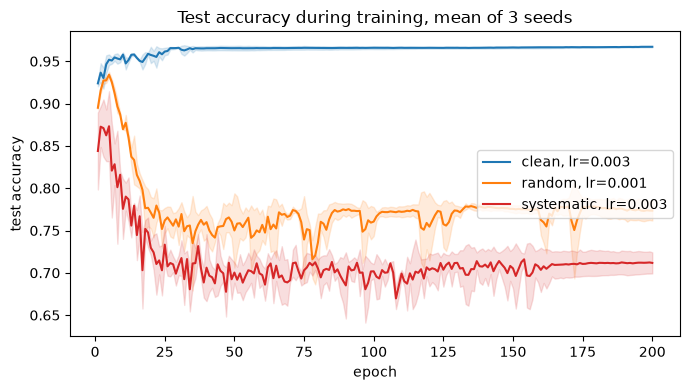

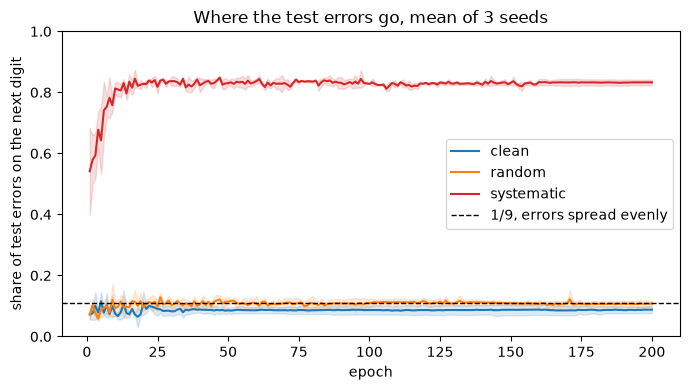

In [83]:
def mean_curve(condition, key):
    # Per-epoch mean and sd of one metric, over the 3 formal seeds of a condition
    lr = selected_lr[condition]
    curves = []
    for r in all_results:
        if r["config"]["condition"] == condition and r["config"]["lr"] == lr:
            curves.append(r["metrics"][key])    # a list of 200 values, one per epoch
    curves = np.array(curves)                    # shape (3, 200): seeds x epochs
    mean = curves.mean(axis=0)                   # average over the 3 seeds, for each epoch
    sd = curves.std(axis=0, ddof=1)              # sample sd, same as pandas std
    return mean, sd


COLOURS = {"clean": "C0", "random": "C1", "systematic": "C3"}
epochs = np.arange(1, EPOCHS + 1)    # 1, 2, ..., 200

# Figure 1: test accuracy per epoch.
fig, ax = plt.subplots(figsize=(7, 4))
for condition in CONDITIONS_NB1 + CONDITIONS_NB2:
    mean, sd = mean_curve(condition, "test_acc")
    ax.plot(epochs, mean, color=COLOURS[condition], label=f"{condition}, lr={selected_lr[condition]:g}")
    ax.fill_between(epochs, mean - sd, mean + sd, color=COLOURS[condition], alpha=0.15)
ax.set_xlabel("epoch")
ax.set_ylabel("test accuracy")
ax.set_title("Test accuracy during training, mean of 3 seeds")
ax.legend(loc="center right")    # the empty area between the curves
fig.tight_layout()
fig.savefig(FIG_DIR / "nb2_test_acc.png", dpi=150)
plt.show()

# Figure 2: share of test errors that fall on the next digit, per epoch.
fig, ax = plt.subplots(figsize=(7, 4))
for condition in CONDITIONS_NB1 + CONDITIONS_NB2:
    mean, sd = mean_curve(condition, "test_err_next")
    ax.plot(epochs, mean, color=COLOURS[condition], label=condition)
    ax.fill_between(epochs, mean - sd, mean + sd, color=COLOURS[condition], alpha=0.15)
ax.axhline(1 / 9, color="k", ls="--", lw=1, label="1/9, errors spread evenly")
ax.set_xlabel("epoch")
ax.set_ylabel("share of test errors on the next digit")
ax.set_ylim(0, 1)
ax.set_title("Where the test errors go, mean of 3 seeds")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "nb2_test_err_next.png", dpi=150)
plt.show()


### 6.2 Verdicts for P5 and P6

Each threshold from the predictions cell is checked separately, and a prediction is **supported** only if all of its thresholds are met. The table also records the numbers behind each verdict, and it is saved to `results/nb2_prediction_summary.csv`.

**Note on the baseline numbers.** The predictions cell quoted NB1 results from an earlier run on another machine: random seeds 92.85%, 93.47% and 93.91%. All 36 runs used here were produced on one machine, and the random seeds are 93.08%, 93.39% and 93.76%, with the same mean of 93.41%. The thresholds are defined relative to the random runs, the mean and the lowest seed, so they are applied to the runs actually compared here. The predictions cell itself is left unchanged.


In [84]:
# Test accuracy of early stopping, one value per seed, for each condition.
sys_acc = formal[formal["condition"] == "systematic"]["test_acc_at_stop"]
rnd_acc = formal[formal["condition"] == "random"]["test_acc_at_stop"]

# P5: two thresholds
p5_gap = rnd_acc.mean() - sys_acc.mean()
p5_a = p5_gap >= 0.02                    # systematic mean at least 2 points below random
p5_b = sys_acc.max() < rnd_acc.min()     # every systematic seed below the lowest random seed
p5_ok = p5_a and p5_b

# P6: share of test errors on the next digit at the early-stopping epoch, mean over seeds.
next_share = {}
for condition in CONDITIONS_NB1 + CONDITIONS_NB2:
    rows_c = formal[formal["condition"] == condition]
    next_share[condition] = rows_c["test_err_next_at_stop"].mean()

p6_ok = (next_share["systematic"] >= 0.50
         and next_share["random"] < 0.20
         and next_share["clean"] < 0.20)

print("P5")
print(f"  random mean {rnd_acc.mean():.4f}, systematic mean {sys_acc.mean():.4f}, gap {p5_gap:.4f} (need >= 0.02): {p5_a}")
print(f"  highest systematic seed {sys_acc.max():.4f}, lowest random seed {rnd_acc.min():.4f}: {p5_b}")
print("P6")
for condition in next_share:
    print(f"  {condition}: {next_share[condition]:.3f}")
print("  systematic seeds:", [round(v, 3) for v in formal[formal["condition"] == "systematic"]["test_err_next_at_stop"]])

# Verdict table, saved with the other results.
verdicts = pd.DataFrame([
    {
        "prediction": "P5: early stopping protects less under systematic than random noise",
        "verdict": "supported" if p5_ok else "not supported",
        "evidence": (f"random {rnd_acc.mean():.4f} vs systematic {sys_acc.mean():.4f}, gap {p5_gap:.4f}; "
                     f"highest systematic seed {sys_acc.max():.4f} < lowest random seed {rnd_acc.min():.4f}: {p5_b}"),
    },
    {
        "prediction": "P6: under systematic noise, test errors concentrate on the next digit",
        "verdict": "supported" if p6_ok else "not supported",
        "evidence": (f"next-digit share at stop: systematic {next_share['systematic']:.3f}, "
                     f"random {next_share['random']:.3f}, clean {next_share['clean']:.3f}"),
    },
])
verdicts.to_csv(RESULTS_DIR / "nb2_prediction_summary.csv", index=False)
verdicts


P5
  random mean 0.9341, systematic mean 0.9008, gap 0.0333 (need >= 0.02): True
  highest systematic seed 0.9082, lowest random seed 0.9308: True
P6
  clean: 0.089
  random: 0.088
  systematic: 0.555
  systematic seeds: [0.508, 0.586, 0.57]


,prediction,verdict,evidence
0,P5: early stopping protects less under systema...,supported,"random 0.9341 vs systematic 0.9008, gap 0.0333..."
1,"P6: under systematic noise, test errors concen...",supported,"next-digit share at stop: systematic 0.555, ra..."


## 7. Alternative explanations

P5 and P6 hold, but the lower accuracy under systematic noise could have other causes. Each check below uses the runs already trained; nothing new is trained.

| Alternative explanation | How it is checked |
|---|---|
| Accuracy falls simply because training lasts 200 epochs | The clean reference is trained for as long; its accuracy should not fall. |
| The selected images, the ones that get corrupted, are harder in themselves | In the clean condition their labels are correct, so they should be learned as fast as the other images. |
| The noisy validation set picks a poor stopping epoch under systematic noise | Compare the early-stopping epoch with the test-optimal epoch. This is the question left open in the predictions cell. |
| Systematic noise only makes the task harder overall | Test errors would then be spread over all digits. P6 and the second figure in 6.1 show that they fall on the next digit instead. |

**7.1** runs the first three checks. **7.2** looks at the mechanism directly: what the network predicts for the corrupted training images early in training, under random and under systematic noise.


In [85]:
# Check 1: does test accuracy fall just because training is long?
# The clean reference is trained for the same 200 epochs.
clean_rows = formal[formal["condition"] == "clean"]
print("Check 1, clean reference")
print(f"  best test acc {clean_rows['max_test_acc'].mean():.4f}, "
      f"mean of last 10 epochs {clean_rows['test_acc_last10'].mean():.4f}")

# Check 2: are the selected images harder in themselves?
# In the clean condition their labels are correct, so compare them with the other images.
sel_mean, _ = mean_curve("clean", "selected_pred_true")
non_mean, _ = mean_curve("clean", "nonselected_pred_true")
print("\nCheck 2, clean condition: training accuracy on selected vs non-selected images")
for epoch in [1, 5, 20, 200]:
    print(f"  epoch {epoch:3d}: selected {sel_mean[epoch - 1]:.3f}, non-selected {non_mean[epoch - 1]:.3f}")

# Check 3: does the noisy validation set pick a good stopping epoch?
# gap_to_optimal = best test accuracy - test accuracy at the chosen epoch.
print("\nCheck 3, early-stopping epoch vs test-optimal epoch")
print(formal[["condition", "seed", "early_stop_epoch", "optimal_test_epoch", "gap_to_optimal"]].to_string(index=False))


Check 1, clean reference
  best test acc 0.9675, mean of last 10 epochs 0.9670

Check 2, clean condition: training accuracy on selected vs non-selected images
  epoch   1: selected 0.947, non-selected 0.943
  epoch   5: selected 0.990, non-selected 0.989
  epoch  20: selected 0.995, non-selected 0.996
  epoch 200: selected 1.000, non-selected 1.000

Check 3, early-stopping epoch vs test-optimal epoch
 condition  seed  early_stop_epoch  optimal_test_epoch  gap_to_optimal
     clean     0                65                 197          0.0016
     clean     1               149                 200          0.0016
     clean     2                59                  45          0.0003
    random     0                 5                   5          0.0000
    random     1                 5                   5          0.0000
    random     2                 5                   5          0.0000
systematic     0                 3                   3          0.0000
systematic     1            

### 7.2 What the network predicts for the corrupted training images

For the training images whose labels were changed, the figure shows the share predicted as their **true digit** (solid lines) and as their **given wrong label** (dashed lines), over the first 40 epochs. Under random noise the given label is one of nine digits; under systematic noise it is always the next digit.


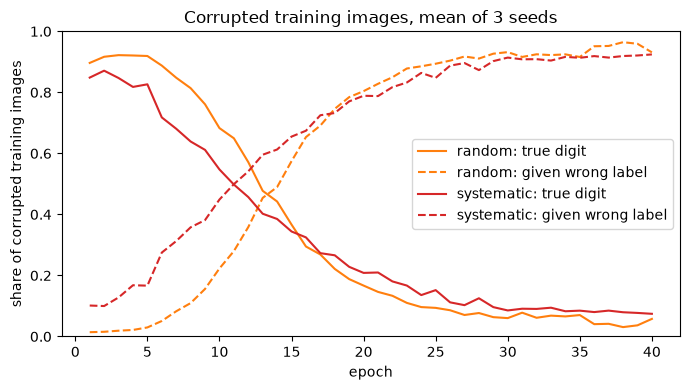

epoch 5, random: true digit 0.919, given wrong label 0.030
epoch 5, systematic: true digit 0.826, given wrong label 0.167


In [86]:
# Corrupted training images: predicted as the true digit, or as the given wrong label?
SHOW = 40    # the first 40 epochs, where the two conditions differ most
x = epochs[:SHOW]

fig, ax = plt.subplots(figsize=(7, 4))
for condition in ["random", "systematic"]:
    true_mean, _ = mean_curve(condition, "selected_pred_true")
    given_mean, _ = mean_curve(condition, "selected_pred_given")
    ax.plot(x, true_mean[:SHOW], color=COLOURS[condition], label=f"{condition}: true digit")
    ax.plot(x, given_mean[:SHOW], color=COLOURS[condition], ls="--", label=f"{condition}: given wrong label")
ax.set_xlabel("epoch")
ax.set_ylabel("share of corrupted training images")
ax.set_ylim(0, 1)
ax.set_title("Corrupted training images, mean of 3 seeds")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "nb2_corrupted_predictions.png", dpi=150)
plt.show()

# The same numbers at epoch 5, close to where early stopping happens.
for condition in ["random", "systematic"]:
    true_mean, _ = mean_curve(condition, "selected_pred_true")
    given_mean, _ = mean_curve(condition, "selected_pred_given")
    print(f"epoch 5, {condition}: true digit {true_mean[4]:.3f}, given wrong label {given_mean[4]:.3f}")


### 7.3 Reading

- **Training length is not the cause.** The clean reference keeps its accuracy for all 200 epochs: its best test accuracy and its last-10 mean differ by less than 0.1 percentage point.
- **The selected images are not harder.** In the clean condition, the selected and non-selected images reach the same training accuracy at every epoch checked.
- **The noisy validation set still picks the right epoch.** Under both random and systematic noise, the early-stopping epoch is the test-optimal epoch in every seed, so `gap_to_optimal` is 0. The worry from the predictions cell, that a learned wrong rule could mislead the noisy validation set, did not happen in these runs. Early stopping therefore does not fail under systematic noise because it stops at the wrong time; it protects less because the best point it can reach is lower.
- **The wrong rule is learned early.** By epoch 5, close to the stopping epoch, systematic noise already pulls a clearly larger share of corrupted training images to their given wrong label than random noise does, and fewer to their true digit. This is the mechanism proposed in the theory: consistent wrong labels act like a second rule and are learned alongside the true one, not only memorised late.


## 8. Sensitivity check: Fashion-MNIST

*The design of this section, including the thresholds, was written before any sensitivity run was trained.*

The main result comes from a single setting. This check changes one thing, the **dataset**, and keeps everything else, to see whether P5 and P6 still hold.

**Why the dataset.** "MNIST only" is the largest limit on how far the main result can be generalised. Fashion-MNIST has exactly the same format as MNIST: 28 × 28 grey images, 10 classes, 60,000 training and 10,000 test images. So the split indices, the noise code, the model and `train_one_run` are all reused unchanged; only the data loader is new. It is also a harder task, because several classes look alike, for example shirt, T-shirt and pullover.

**Pair flipping on Fashion-MNIST.** Class c is relabelled as class c + 1 in the dataset's label order, for example T-shirt → trouser and ankle boot → T-shirt. As with digits, the next class is not chosen to look similar; it is simply a consistent wrong label.

**Design.**

- Conditions: random and systematic only, since P5 compares these two. The clean reference is not repeated.
- The same four learning rates and three seeds: 2 × 4 × 3 = 24 runs. The learning rate is selected per condition by the same rule as in section 5, the highest mean early-stopping noisy-validation accuracy.
- Runs are saved in `results/sensitivity_fashion/`, so they cannot overwrite the main MNIST runs.
- The same thresholds are applied. P5: the systematic mean is at least 2 percentage points below the random mean, and every systematic seed is below the lowest random seed. P6: the next-class share of test errors at the early-stopping epoch is ≥ 0.50 for systematic and < 0.20 for random.

Sections: **8.1** data, **8.2** runs, **8.3** results and verdicts.


### 8.1 Fashion-MNIST data

Same indices and preprocessing as section 1: training images `[0:10000]`, validation images `[50000:55000]`, all 10,000 test images, pixels scaled to 0–1 and flattened to 784.


In [87]:
# Same split and preprocessing as load_mnist_split; only the dataset changes.
def load_fashion_split():
    tf = transforms.ToTensor()
    train_full = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=tf)
    test_full = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=tf)

    def to_tensors(dataset):
        xs, ys = [], []
        for x, y in dataset:
            xs.append(x.reshape(-1))    # 28 x 28 -> 784
            ys.append(int(y))
        return torch.stack(xs), torch.tensor(ys, dtype=torch.long)

    train_x, train_y = to_tensors(Subset(train_full, list(range(0, 10_000))))
    val_x, val_y = to_tensors(Subset(train_full, list(range(50_000, 55_000))))
    test_x, test_y = to_tensors(test_full)
    return train_x, train_y, val_x, val_y, test_x, test_y


fashion_data = load_fashion_split()
print("train:", tuple(fashion_data[0].shape), "counts:", np.bincount(fashion_data[1].numpy()))
print("val:  ", tuple(fashion_data[2].shape), "counts:", np.bincount(fashion_data[3].numpy()))
print("test: ", tuple(fashion_data[4].shape), "counts:", np.bincount(fashion_data[5].numpy()))

# Show what pair flipping means for these classes: c -> c + 1.
names = datasets.FashionMNIST.classes
for c in range(NUM_CLASSES):
    print(f"  {names[c]} -> {names[(c + 1) % NUM_CLASSES]}")


train: (10000, 784) counts: [ 942 1027 1016 1019  974  989 1021 1022  990 1000]
val:   (5000, 784) counts: [502 491 518 513 523 493 503 505 453 499]
test:  (10000, 784) counts: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
  T-shirt/top -> Trouser
  Trouser -> Pullover
  Pullover -> Dress
  Dress -> Coat
  Coat -> Sandal
  Sandal -> Shirt
  Shirt -> Sneaker
  Sneaker -> Bag
  Bag -> Ankle boot
  Ankle boot -> T-shirt/top


### 8.2 Sensitivity runs

The same three cases as in 4.2b: with `QUICK = True` the 24 cached runs are loaded, or the cell stops if any is missing; with `QUICK = False` each run is loaded if its file exists, otherwise trained and saved. `train_one_run` records `"MNIST"` as the dataset in its config, so the dataset field is corrected before each run is saved.


In [88]:
# Sensitivity runs are saved in their own folder, so they never overwrite the main MNIST runs.
SENS_DIR = RESULTS_DIR / "sensitivity_fashion"
SENS_DIR.mkdir(exist_ok=True)
CONDITIONS_SENS = ["random", "systematic"]


def sens_path(condition, lr, seed):
    return SENS_DIR / f"{condition}_lr{lr:g}_seed{seed}.json"


# Check which of the 24 files exist: 2 conditions x 4 learning rates x 3 seeds.
sens_flags = []
for condition in CONDITIONS_SENS:
    for lr in LR_CANDIDATES:
        for seed in SEEDS:
            sens_flags.append(sens_path(condition, lr, seed).exists())
SENS_COMPLETE = all(sens_flags)
print(f"sensitivity cache: {sum(sens_flags)}/{len(sens_flags)} files present")

sens_results = []
if QUICK and SENS_COMPLETE:
    # Case 1: everything is cached, so load it.
    for condition in CONDITIONS_SENS:
        for lr in LR_CANDIDATES:
            for seed in SEEDS:
                sens_results.append(json.loads(sens_path(condition, lr, seed).read_text()))
    print(f"loaded {len(sens_results)} cached sensitivity runs")

elif QUICK:
    # Case 2: some runs are missing.
    raise FileNotFoundError(
        f"only {sum(sens_flags)}/{len(sens_flags)} sensitivity runs are cached; "
        "set QUICK = False to train them"
    )

else:
    # Case 3: train the missing runs, load the finished ones.
    for condition in CONDITIONS_SENS:
        for lr in LR_CANDIDATES:
            for seed in SEEDS:
                path = sens_path(condition, lr, seed)
                print(f"\n=== Fashion-MNIST | {condition} | lr={lr:g} | seed={seed} ===")
                if path.exists():
                    print("  cached, loading")
                    result = json.loads(path.read_text())
                else:
                    result = train_one_run(condition, lr, seed, fashion_data)
                    result["config"]["dataset"] = "FashionMNIST"    # train_one_run always writes "MNIST"
                    path.write_text(json.dumps(result, indent=2))
                sens_results.append(result)
    print(f"\nsensitivity runs complete: {len(sens_results)}")


sensitivity cache: 0/24 files present

=== Fashion-MNIST | random | lr=0.0001 | seed=0 ===
  epoch  20/200 | train 0.622 | val noisy 0.592 | test 0.836
  epoch  40/200 | train 0.646 | val noisy 0.593 | test 0.829
  epoch  60/200 | train 0.690 | val noisy 0.582 | test 0.821
  epoch  80/200 | train 0.737 | val noisy 0.558 | test 0.781
  epoch 100/200 | train 0.780 | val noisy 0.539 | test 0.742
  epoch 120/200 | train 0.847 | val noisy 0.528 | test 0.737
  epoch 140/200 | train 0.890 | val noisy 0.512 | test 0.712
  epoch 160/200 | train 0.921 | val noisy 0.497 | test 0.689
  epoch 180/200 | train 0.943 | val noisy 0.488 | test 0.678
  epoch 200/200 | train 0.963 | val noisy 0.492 | test 0.682

=== Fashion-MNIST | random | lr=0.0001 | seed=1 ===
  epoch  20/200 | train 0.616 | val noisy 0.590 | test 0.832
  epoch  40/200 | train 0.644 | val noisy 0.588 | test 0.829
  epoch  60/200 | train 0.686 | val noisy 0.579 | test 0.809
  epoch  80/200 | train 0.731 | val noisy 0.559 | test 0.767
  

### 8.3 Results and verdicts on Fashion-MNIST

The same steps as sections 5 and 6, in one cell: one row per run, the learning-rate table, the formal runs at the selected rates, and the P5 and P6 thresholds. The last table puts the MNIST and Fashion-MNIST results side by side.


In [89]:
# One row per run, as in 5.1.
rows = []
for r in sens_results:
    cfg = r["config"]
    es = r["early_stop"]
    rows.append({
        "condition": cfg["condition"],
        "lr": cfg["lr"],
        "seed": cfg["seed"],
        "early_stop_epoch": es["epoch"],
        "early_stop_val_noisy": es["val_acc_noisy"],
        "test_acc_at_stop": es["test_acc_at_stop"],
        "test_acc_last10": es["test_acc_last10_mean"],
        "gap_to_optimal": es["gap_to_optimal_test_acc"],
        "test_err_next_at_stop": r["metrics"]["test_err_next"][es["epoch"] - 1],
    })
sens_df = pd.DataFrame(rows)

# Learning-rate table and selection, as in 5.2. Only noisy validation accuracy is used to choose.
sens_tune = sens_df.groupby(["condition", "lr"]).agg(
    val_noisy_mean=("early_stop_val_noisy", "mean"),
    test_stop_mean=("test_acc_at_stop", "mean"),
    test_last10_mean=("test_acc_last10", "mean"),
).reset_index()

sens_lr = {}
for condition in CONDITIONS_SENS:
    rows_c = sens_tune[sens_tune["condition"] == condition]
    best = rows_c["val_noisy_mean"].idxmax()
    sens_lr[condition] = float(sens_tune.loc[best, "lr"])
print("selected learning rates on Fashion-MNIST:", sens_lr)
print(sens_tune.to_string(index=False))

# Formal runs at the selected rates, as in 5.3.
parts = []
for condition in CONDITIONS_SENS:
    parts.append(sens_df[(sens_df["condition"] == condition) & (sens_df["lr"] == sens_lr[condition])])
sens_formal = pd.concat(parts)
print()
print(sens_formal[["condition", "lr", "seed", "early_stop_epoch", "test_acc_at_stop",
                   "test_acc_last10", "gap_to_optimal", "test_err_next_at_stop"]].to_string(index=False))

# P5 and P6 with the same thresholds as on MNIST.
f_sys = sens_formal[sens_formal["condition"] == "systematic"]
f_rnd = sens_formal[sens_formal["condition"] == "random"]
f_gap = f_rnd["test_acc_at_stop"].mean() - f_sys["test_acc_at_stop"].mean()
f_p5 = f_gap >= 0.02 and f_sys["test_acc_at_stop"].max() < f_rnd["test_acc_at_stop"].min()
f_p6 = f_sys["test_err_next_at_stop"].mean() >= 0.50 and f_rnd["test_err_next_at_stop"].mean() < 0.20

# MNIST and Fashion-MNIST side by side.
m_sys = formal[formal["condition"] == "systematic"]
m_rnd = formal[formal["condition"] == "random"]
compare = pd.DataFrame([
    {"dataset": "MNIST",
     "random_test_at_stop": m_rnd["test_acc_at_stop"].mean(),
     "systematic_test_at_stop": m_sys["test_acc_at_stop"].mean(),
     "gap_random_minus_systematic": m_rnd["test_acc_at_stop"].mean() - m_sys["test_acc_at_stop"].mean(),
     "systematic_next_share": m_sys["test_err_next_at_stop"].mean(),
     "P5": "supported" if p5_ok else "not supported",
     "P6": "supported" if p6_ok else "not supported"},
    {"dataset": "Fashion-MNIST",
     "random_test_at_stop": f_rnd["test_acc_at_stop"].mean(),
     "systematic_test_at_stop": f_sys["test_acc_at_stop"].mean(),
     "gap_random_minus_systematic": f_gap,
     "systematic_next_share": f_sys["test_err_next_at_stop"].mean(),
     "P5": "supported" if f_p5 else "not supported",
     "P6": "supported" if f_p6 else "not supported"},
])
compare.to_csv(RESULTS_DIR / "nb2_sensitivity_fashion.csv", index=False)
compare


selected learning rates on Fashion-MNIST: {'random': 0.0003, 'systematic': 0.003}
 condition     lr  val_noisy_mean  test_stop_mean  test_last10_mean
    random 0.0001        0.596267        0.837100          0.676620
    random 0.0003        0.596933        0.837067          0.668807
    random 0.0010        0.595600        0.834367          0.694233
    random 0.0030        0.591600        0.828667          0.659803
systematic 0.0001        0.583867        0.800800          0.642323
systematic 0.0003        0.590800        0.809733          0.623913
systematic 0.0010        0.593600        0.827733          0.633283
systematic 0.0030        0.596200        0.828133          0.617987

 condition     lr  seed  early_stop_epoch  test_acc_at_stop  test_acc_last10  gap_to_optimal  test_err_next_at_stop
    random 0.0003     0                14            0.8400          0.66596          0.0000               0.040000
    random 0.0003     1                12            0.8343          0.66

,dataset,random_test_at_stop,systematic_test_at_stop,gap_random_minus_systematic,systematic_next_share,P5,P6
0,MNIST,0.934100,0.900767,0.033333,0.554676,supported,supported
1,Fashion-MNIST,0.837067,0.828133,0.008933,0.166864,not supported,not supported


### 8.4 Reading the Fashion-MNIST result

*Written after the 24 Fashion-MNIST runs were trained. The thresholds are the ones fixed in section 8 before training.*

**Neither prediction holds on Fashion-MNIST.**

| | MNIST | Fashion-MNIST |
|---|---|---|
| random, test accuracy at stop | 0.934 | 0.837 |
| systematic, test accuracy at stop | 0.901 | 0.828 |
| gap (random − systematic) | 3.3 pp, gap/SE 7.3 | 0.9 pp, gap/SE 1.0 |
| systematic, next-class share of test errors at stop | 0.55 | 0.17 |
| P5 / P6 | supported / supported | not supported / not supported |

- **P5.** The gap is 0.9 percentage points, below the 2 pp threshold, and gap/SE is about 1, so it is within seed noise. The seeds also overlap: systematic seed 0 (0.843) is higher than every random seed (0.834 to 0.840). The systematic seeds are much more spread out (sd 0.015, against 0.003 for random).
- **P6.** At the early-stopping epoch, only 0.17 of the systematic test errors go to the next class (seeds: 0.10, 0.18, 0.22), far below 0.50. Random is 0.04, so systematic is still higher, but not at the predicted level.

**What happened instead.** Systematic noise is not harmless on Fashion-MNIST, but the network learns it later. By epoch 200 the systematic next-class share has risen to about 0.61 in every seed (random: 0.07 to 0.10). The mean test accuracy over the last 10 epochs is 0.618 for systematic and 0.669 for random. So the flipped rule is still learned in the end, as on MNIST. On Fashion-MNIST, however, the noisy-validation peak (epochs 9 to 11 for systematic) comes before most of that learning, so early stopping cuts training before most of the damage. We did not test why the timing is different on the two datasets.

**A caveat on the learning rate.** Following the protocol, the learning rate was chosen separately for each condition: 0.0003 for random and 0.003 for systematic. If systematic is read at random's rate of 0.0003 instead, its mean is 0.810: a 2.7 pp gap, with every systematic seed below every random seed. Part of the closing of the gap therefore comes from tuning. This comparison is exploratory and not the pre-registered test, so the verdicts above stand.

**What this means for the main result.** On MNIST, P5 and P6 are supported. They do not carry over to Fashion-MNIST under the same protocol. So the conclusion has to be limited to the setting tested: on MNIST, systematic noise clearly reduced how well early stopping protected the network; on Fashion-MNIST, with per-condition tuning, the difference was within seed noise. With only 3 seeds per condition, a small effect on Fashion-MNIST cannot be ruled out.

## 9. Conclusions and limitations

### 9.1 Answer to the research question

*Does early stopping still protect a network from label noise when the mistakes are systematic rather than random?*

**On MNIST: partly, and less than under random noise.** With 30% noise, early stopping kept test accuracy at 0.934 under random noise but only 0.901 under systematic pair-flip noise, a gap of 3.3 percentage points (gap/SE 7.3, no overlap between seeds). The clean reference reached 0.966. Without early stopping, both noisy conditions fall much further: the last-10-epoch means are 0.774 (random) and 0.712 (systematic). So early stopping still helps a lot under systematic noise, but it recovers less.

**Why it protects less.** The noisy validation set still chose the test-optimal epoch in every seed (section 7.3). Early stopping did not fail by stopping at the wrong time. The best point available was lower, because the network starts learning the consistent wrong rule from the first few epochs. At the stopping epoch, 55% of systematic test errors already went to the next digit (P6), against 9% under random noise.

**On Fashion-MNIST: no clear difference.** With the same protocol, the gap was 0.9 pp (gap/SE 1.0) and the next-class share at stop was 0.17, so neither P5 nor P6 held (section 8.4). The wrong rule was still learned there, but mostly after the early-stopping epoch. The MNIST result therefore depends on the dataset and should not be read as a general rule.

**Summary.** Under systematic noise, early stopping is not a reliable defence in general: how much it protects depends on whether the wrong rule is learned before or after the noisy-validation peak. On MNIST it was learned before the peak and cost 3.3 pp. On Fashion-MNIST it was learned mostly after the peak and cost about 1 pp, which is within seed noise.

### 9.2 Limitations

- **Model and training.** One model only: a 784-512-512-10 MLP trained with Adam, with no weight decay, dropout or data augmentation. CNNs or regularised models may learn the wrong rule at a different speed.
- **Data size.** Training used 10,000 images and validation 5,000, not the full 60,000 training images.
- **One noise setting.** Only 30% noise, and only one systematic pattern, c → c + 1. This pattern pairs classes that do not look alike. Flips between similar classes (for example 4 → 9, or shirt → T-shirt) could behave differently.
- **Few seeds.** Each configuration has 3 seeds. That was enough to separate the conditions on MNIST, but not to rule out a small effect on Fashion-MNIST.
- **Learning-rate tuning.** The learning rate was chosen per condition from noisy validation accuracy. On Fashion-MNIST this choice explains part of the small gap: at random's learning rate the gap would be 2.7 pp (exploratory, section 8.4).
- **Early-stopping rule.** Early stopping was applied after training, by picking the epoch with the best noisy validation accuracy over all 200 epochs. A patience-based rule that stops during training could pick a different epoch.
- **Hardware.** All runs were done on one laptop CPU, not on the dl2026 environment. Results should be repeatable with the saved seeds, but exact numbers may differ slightly on other hardware.

### 9.3 Next steps

1. **More seeds on Fashion-MNIST**, for example 10, to see whether the 0.9 pp gap is a real but small effect or zero.
2. **A fixed learning rate across conditions**, as a second pre-registered test, to separate the effect of the noise from the effect of tuning.
3. **Higher systematic noise**, for example 45%, which approaches the point (50% for pair flips) where the wrong label becomes as common as the true label and the noisy validation set can no longer tell them apart.
4. **Similarity-based flips**, for example taken from a clean model's confusion matrix, which are closer to the mistakes real annotators make.
5. **A CNN**, to check whether the timing of rule learning, and therefore the protection given by early stopping, depends on the model.